# 00 — Audit & Préparation des données ENEDIS (2019–2024)

Ce notebook exécute le pipeline d'ingestion `src/preprocessing.py` (Polars $\rightarrow$ Parquet), contrôle l'intégrité du périmètre géographique sur la période 2019–2024 et synthétise les premiers enseignements structurels de la série.

In [5]:
pip install polars

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.config import PROCESSED_DATA_DIR
from src.preprocessing import run_pipeline

# 1. Exécution du pipeline Polars -> Parquet
run_pipeline()

Exécution du pipeline d'agrégation en cours...
[OK] france_annuel.parquet généré (6 lignes)
[OK] regions_annuel.parquet généré (76 lignes)
[OK] departements_annuel.parquet généré (562 lignes)
[OK] iris_annuel.parquet généré (53311 lignes)


In [7]:
# 2. Chargement des tables agrégées
df_fr = pd.read_parquet(PROCESSED_DATA_DIR / "france_annuel.parquet")
df_reg = pd.read_parquet(PROCESSED_DATA_DIR / "regions_annuel.parquet")
df_dept = pd.read_parquet(PROCESSED_DATA_DIR / "departements_annuel.parquet")

display(df_fr)

,annee,nb_adresses,nb_regions,nb_departements,nb_iris,nb_logements_total,conso_totale_mwh,conso_totale_twh,conso_moyenne_logement_mwh
0,2019,174762,13,94,8863,3795614.0,1.002807e+07,10.028072,2.642016
1,2020,174763,13,94,8951,3821767.0,1.015355e+07,10.153546,2.656767
2,2021,174763,13,94,8765,3815911.0,1.022878e+07,10.228780,2.680560
3,2022,174762,12,93,9015,3891350.0,9.528490e+06,9.528490,2.448634
4,2023,174763,12,93,8916,3899774.0,9.226011e+06,9.226011,2.365781
5,2024,174762,13,94,8801,3897823.0,9.073964e+06,9.073964,2.327957


Département absent en 2022–2023 : {None}


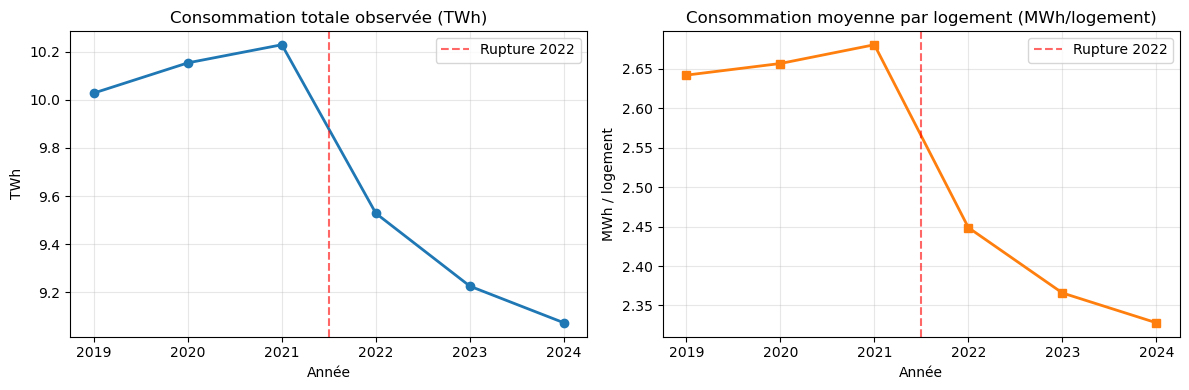

In [8]:
# 3. Diagnostic de couverture géographique et visualisation
depts_2021 = set(df_dept[df_dept["annee"] == 2021]["code_departement"])
depts_2022 = set(df_dept[df_dept["annee"] == 2022]["code_departement"])
print("Département absent en 2022–2023 :", depts_2021 - depts_2022)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df_fr["annee"], df_fr["conso_totale_twh"], marker="o", linewidth=2, color="#1f77b4")
axes[0].axvline(2021.5, color="red", linestyle="--", alpha=0.6, label="Rupture 2022")
axes[0].set_title("Consommation totale observée (TWh)")
axes[0].set_xlabel("Année")
axes[0].set_ylabel("TWh")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_fr["annee"], df_fr["conso_moyenne_logement_mwh"], marker="s", linewidth=2, color="#ff7f0e")
axes[1].axvline(2021.5, color="red", linestyle="--", alpha=0.6, label="Rupture 2022")
axes[1].set_title("Consommation moyenne par logement (MWh/logement)")
axes[1].set_xlabel("Année")
axes[1].set_ylabel("MWh / logement")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Synthèse de l'audit des données et implications méthodologiques

L'exploration initiale du fichier brut ENEDIS (`1 048 575` enregistrements) et des agrégations générées met en évidence **quatre enseignements structurants** pour la suite du projet :

1. **Périmètre de l'échantillon et représentativité :**
   - Le fichier brut contient exactement $1\,048\,575$ lignes (correspondant au plafond d'export d'une feuille Excel de $2^{20} - 1$ lignes), réparties de manière parfaitement équilibrée sur **6 années (2019 à 2024)** à raison d'environ `174 762` adresses par an (aucune ligne perdue après nettoyage).
   - Cet échantillon couvre entre **3,80 et 3,90 millions de logements** pour une consommation annuelle comprise entre **9,07 et 10,23 TWh**, soit environ **12,5 % du parc résidentiel français** (~30 millions de résidences, ~150 TWh/an). Nos prévisions porteront donc soit directement sur ce périmètre ENEDIS observé, soit par extrapolation nationale via la consommation unitaire moyenne par logement.

2. **Rupture structurelle marquée en 2022 (crise énergétique et sobriété) :**
   - **Régime 2019–2021 (hausse) :** La consommation totale progresse régulièrement de `10,03 TWh` en 2019 à `10,15 TWh` en 2020 (+1,25 %, effet des confinements) puis `10,23 TWh` en 2021 (+0,74 %), portée par une consommation unitaire passant de `2,64` à `2,68 MWh/logement`.
   - **Régime 2022–2024 (décrochage) :** Dès 2022, la consommation chute brutalement de **-6,85 %** (`9,53 TWh`), puis poursuit sa baisse en 2023 (`9,23 TWh`, -3,17 %) et 2024 (`9,07 TWh`, -1,65 %), **alors même que le parc de logements raccordés continue de croître** (`3,80M` $\rightarrow$ `3,90M`). La consommation moyenne par logement recule ainsi de **-13,2 %** entre 2021 et 2024 (`2,68` $\rightarrow$ `2,33 MWh/logement`), traduisant l'impact de la flambée des prix de l'électricité, des mesures de sobriété hivernale et de l'amélioration de l'efficacité énergétique.

3. **Stabilité de la couverture géographique :**
   - L'échantillon couvre **13 régions** et **94 départements** en 2019, 2020, 2021 et 2024, mais **12 régions / 93 départements** en 2022 et 2023 (absence ponctuelle d'un territoire insulaire/spécifique sur ces deux millésimes). Cet écart mineur sera neutralisé dans les analyses régionales et panel en travaillant sur un périmètre géographique constant ou en normalisant par logement.

4. **Conséquences sur la stratégie de modélisation :**
   - La profondeur temporelle macro étant courte ($T = 6$ observations annuelles) et marquée par un changement de régime en 2022, les modèles purement univariés classiques (lissages, régressions, ARIMA) serviront de **références (*baselines*)** mais souffriront d'un faible nombre de degrés de liberté.
   - Pour obtenir des prévisions robustes, nous compléterons l'approche macro par : (i) l'intégration de **variables exogènes** (météo / Degrés Jours Unifiés, prix de l'électricité) à la maille régionale/départementale (`78` à `562` observations), et (ii) une **modélisation panel *bottom-up* à la maille IRIS** (`> 53 000` observations) exploitant la dynamique autorégressive locale et le nombre de logements.